# Cloud Workload Forecasting — Azure VM trace (data-v1)
**Question:** how predictable is this workload, how accurately can the next 2 h be forecast, and what should an infra team do with it?

Pipeline (all logic lives in `src/cwfc`, this notebook calls it so notebook == CLI):
1. verify data → 2. audit → 3. understand workload (EDA) → 4. build targets → 5. chronological 110/24 split →
6. baselines (persistence, moving average, seasonal-naive) → 7. main models (Holt, Ridge, Random Forest, XGBoost) with rolling-origin CV →
8. select on CV **only** → 9. one-time holdout scoring (reporting) → 10. leakage checks → 11. capacity policy.

> Fixes vs. the earlier draft: `avg_cpu` is already a percentage, so the target is **not** multiplied by 10; the split is the required **110 train / 24 holdout** on the full 134-step series (validation is rolling-origin *inside* the 110); checksums are verified per file.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cwfc.data import *
from cwfc.pipeline import *
from cwfc.policy import margin_tradeoff
pd.set_option("display.width", 160)
DATA = "../challenge_data"
print(verify_checksums(DATA))
readings, meta = load_readings(DATA), load_metadata(DATA)

{'vm_cpu_readings.csv.gz': True, 'vm_metadata.csv.gz': True, 'DATA_CARD.md': True}


## 1. Audit — cadence, coverage, missingness, duplicates

In [2]:
display(audit(readings, meta))

,value
reading rows,1340000
distinct VMs,10000
distinct timestamps,134
timestamp spacing (s),300
"duplicate (vm_id, timestamp)",0
null CPU values,0
"avg_cpu outside [0,100]",0
rows violating min<=avg<=max,0
observations per VM (min/max),134 / 134
VMs per timestamp (min/max),10000 / 10000


**Reading:** the release is a perfectly regular panel (10,000 VMs × 134 slots, 300 s spacing, no nulls/duplicates/out-of-range values). The data card says only VMs with a complete 134-slot trace were eligible, so the sample has **no churn by construction** — see next cell.

In [3]:
end = readings.timestamp.max()
life = pd.Series({"created > 0 (born inside window)": int((meta.timestamp_vm_created > 0).sum()),
                  "deleted <= trace end (died inside window)": int((meta.timestamp_vm_deleted <= end).sum()),
                  "earliest deletion timestamp": int(meta.timestamp_vm_deleted.min()), "trace end": int(end)})
display(life.to_frame("value"))
print((meta.timestamp_vm_deleted >= 2591400).mean().round(3), "of VMs live for the whole 30-day source trace")

,value
created > 0 (born inside window),0
deleted <= trace end (died inside window),0
earliest deletion timestamp,40500
trace end,39900


0.821 of VMs live for the whole 30-day source trace


**Why it matters:** `active_vm_count` is constant (10,000) — it is a *survivorship-filtered* population, not live fleet size. No model can add information there; the honest forecast is the constant, and the pipeline must still behave correctly if a different dataset has churn.

In [4]:
series = build_series(readings)
display(series.describe().T.round(3))
train, hold = split_series(series)
print(len(train), len(hold), "| holdout timestamps:", hold.index[0], "->", hold.index[-1])

,count,mean,std,min,25%,50%,75%,max
active_vm_count,134.0,10000.000,0.000,10000.000,10000.000,10000.000,10000.000,10000.000
aggregate_cpu_utilization,134.0,9.388,0.195,8.984,9.251,9.367,9.486,9.912
median_cpu,134.0,5.107,0.074,4.958,5.046,5.103,5.158,5.283
p95_cpu,134.0,37.316,1.579,34.142,36.123,37.148,38.291,41.170
mean_max_cpu,134.0,18.348,0.493,17.528,17.982,18.283,18.525,19.970
share_hot,134.0,0.031,0.004,0.026,0.028,0.030,0.034,0.038


110 24 | holdout timestamps: 33000 -> 39900


## 2. Workload understanding

In [5]:
m = readings.merge(meta[["vm_id","vm_category","virtual_core_bucket","memory_gb_bucket"]], on="vm_id")
print(readings.avg_cpu.describe(percentiles=[.5,.9,.95,.99]).round(2).to_string())
print("\nshare of VM-readings with avg_cpu < 10%:", (readings.avg_cpu<10).mean().round(3), "| >= 50%:", (readings.avg_cpu>=50).mean().round(3))
display(m.groupby("vm_category").avg_cpu.agg(mean="mean", median="median", p95=lambda s: s.quantile(.95)).round(2))
display(m.groupby("virtual_core_bucket").avg_cpu.agg(["mean","median","count"]).round(2))
seg = m.groupby(["timestamp","vm_category"]).avg_cpu.mean().unstack()
print("step-to-step SD of segment mean (pp):"); print(seg.diff().std().round(3).to_string())

count    1340000.00
mean           9.39
std           14.27
min            0.01
50%            5.11
90%           19.60
95%           37.13
99%           87.35
max           99.49

share of VM-readings with avg_cpu < 10%: 0.762 | >= 50%: 0.031


,mean,median,p95
vm_category,,,
Delay-insensitive,8.24,5.15,25.91
Interactive,11.49,5.28,49.41
Unknown,10.23,3.38,52.23


,mean,median,count
virtual_core_bucket,,,
2,9.72,5.51,1009556
24,11.40,6.78,8308
4,7.93,2.90,255672
8,9.70,4.28,65124
>24,6.62,2.64,1340


step-to-step SD of segment mean (pp):
vm_category
Delay-insensitive    0.134
Interactive          0.257
Unknown              0.266


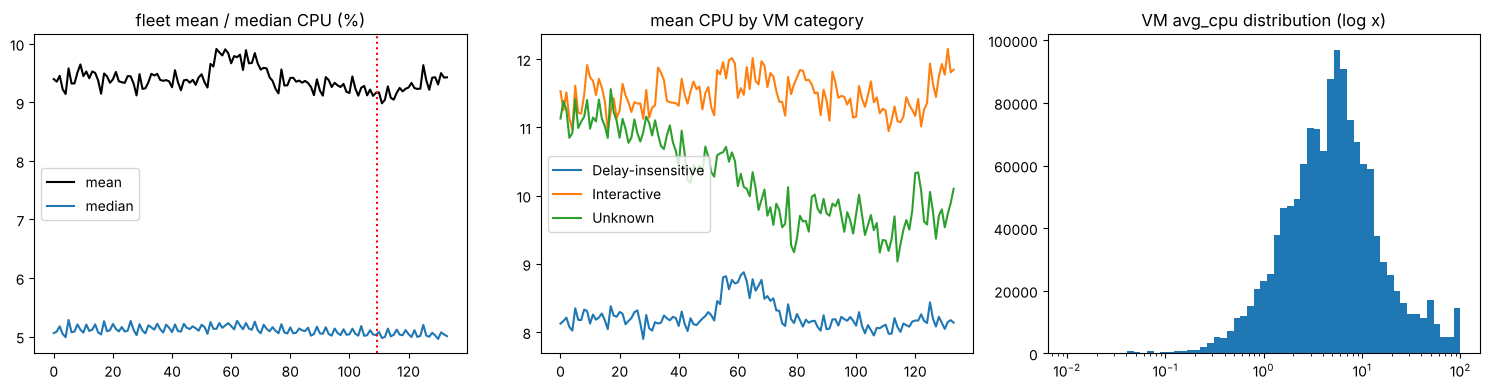

In [6]:
fig, ax = plt.subplots(1,3, figsize=(15,4)); xs = np.arange(len(series))
ax[0].plot(xs, series.aggregate_cpu_utilization, c="k", label="mean"); ax[0].plot(xs, series.median_cpu, label="median"); ax[0].axvline(len(train)-.5, c="r", ls=":"); ax[0].legend(); ax[0].set_title("fleet mean / median CPU (%)")
for c in seg: ax[1].plot(xs, seg[c].to_numpy(), label=c)
ax[1].legend(); ax[1].set_title("mean CPU by VM category")
ax[2].hist(readings.avg_cpu, bins=np.logspace(-2,2,60)); ax[2].set_xscale("log"); ax[2].set_title("VM avg_cpu distribution (log x)")
plt.tight_layout(); plt.show()

In [7]:
y = series.aggregate_cpu_utilization
print("autocorrelation by lag:", {l: round(y[:110].autocorr(l),2) for l in (1,2,6,12,24)})
print("range:", round(y.max()-y.min(),3), "pp  =", round((y.max()-y.min())/y.mean()*100,1), "% of mean")
print("mean steps 0-49 / 50-74 (bump) / 75-109 / holdout:", [round(v,3) for v in (y[:50].mean(), y[50:75].mean(), y[75:110].mean(), y[110:].mean())])
print("peaks:", y.nlargest(3).round(3).to_dict()); print("lows :", y.nsmallest(3).round(3).to_dict())

autocorrelation by lag: {1: np.float64(0.67), 2: np.float64(0.61), 6: np.float64(0.48), 12: np.float64(0.37), 24: np.float64(-0.03)}
range: 0.929 pp  = 9.9 % of mean
mean steps 0-49 / 50-74 (bump) / 75-109 / holdout: [np.float64(9.385), np.float64(9.661), np.float64(9.279), np.float64(9.269)]
peaks: {16500: 9.912, 17400: 9.906, 19500: 9.892}
lows : {33300: 8.984, 33600: 9.043, 34500: 9.046}


**Operational reading.** The *typical* VM is idle (median ≈ 5 %), but the distribution has a heavy tail (p95 ≈ 26 % for Delay-insensitive, ≈ 49–52 % for Interactive/Unknown): fleet-level *mean* CPU is stable (≈ 9.4 %, total swing < 1 pp) while risk lives in individual VMs. Interactive/Unknown segments are ~2× as volatile as Delay-insensitive, so they deserve larger headroom. Only 11 h are observed, so a daily cycle cannot be learned — a one-hour "seasonal naive" is a convention, not real seasonality. A ≈ +0.5 pp level shift occurs around steps 53–72 (≈ 4.5–6 h in); it is the main unpredictable event in the series.

## 3. Forecasting design
* **Horizon:** 24 steps (2 h) at the native 5-min cadence — no resampling, so no mapping is needed.
* **Validation:** expanding-window rolling origin *inside the 110 training steps*: origins 50, 62, 74, 86; each fold trains on rows `[0, o)` and forecasts `[o, o+24)`. The public holdout is never touched.
* **Features at origin t** (only rows ≤ t): deviations of lags 0/1/2/5/11 and 6-step mean from the 12-step level, 12-step std, 1-step diff, level-vs-expanding-mean (mean reversion), and deviations of cross-sectional VM summaries (median, p95, mean max_cpu, share of VMs ≥ 50 %). Models are *pooled direct* learners with horizon *h* as a feature, target = `y[t+h] − level[t]`.
* **Tuning:** tiny grids, scored by the same rolling-origin MAE (training window only).

In [8]:
res = {t: run_target(train, t) for t in TARGETS}
r = res["aggregate_cpu_utilization"]
print("origins:", r.origins, "| tuned:", r.params)
display(r.cv_table.drop(columns="type").round(4))
print("CV-selected model:", r.chosen)

origins: [50, 62, 74, 86] | tuned: {'Ridge': {'alpha': 1000.0}, 'RandomForest': {'max_depth': 3, 'min_samples_leaf': 5}, 'XGBoost': {'max_depth': 3, 'n_estimators': 300}}


,MAE,RMSE,sMAPE%,MASE,Peak_MAE,vs_Persistence%,vs_BestBaseline%
Persistence,0.2056,0.2540,2.1641,1.6653,0.2379,0.0000,0.0000
MovingAvg(12),0.2545,0.2972,2.6810,2.0610,0.2658,-23.7583,-23.7583
SeasonalNaive(12),0.2634,0.3142,2.7667,2.1336,0.3055,-28.1176,-28.1176
Holt,0.2686,0.3253,2.8210,2.1758,0.3022,-30.6517,-30.6517
Ridge,0.2722,0.3042,2.8741,2.2043,0.2874,-32.3664,-32.3664
RandomForest,0.2493,0.2881,2.6310,2.0195,0.2719,-21.2690,-21.2690
XGBoost,0.2497,0.2912,2.6352,2.0223,0.2688,-21.4382,-21.4382
Holt(damped),0.2578,0.3065,2.7092,2.0878,0.2711,-25.3708,-25.3708
Ensemble(main4),0.2554,0.2936,2.6949,2.0685,0.2745,-24.2108,-24.2108


CV-selected model: Persistence


In [9]:
pf = (r.cv_preds.assign(err=lambda d:(d.y-d.pred).abs()).pivot_table(index="model", columns="fold", values="err").loc[ORDER])
display(pf.round(3).rename(columns=lambda c: f"fold{c} (origin {r.origins[c]})"))

fold,fold0 (origin 50),fold1 (origin 62),fold2 (origin 74),fold3 (origin 86)
model,,,,
Persistence,0.268,0.297,0.124,0.132
MovingAvg(12),0.324,0.220,0.355,0.119
SeasonalNaive(12),0.316,0.281,0.355,0.102
Holt,0.339,0.374,0.258,0.103
Ridge,0.339,0.183,0.296,0.272
RandomForest,0.333,0.209,0.306,0.149
XGBoost,0.327,0.233,0.225,0.214
Holt(damped),0.302,0.351,0.249,0.130
Ensemble(main4),0.334,0.239,0.271,0.178


**Reading:** no model wins every fold, and all CV MAEs sit within ≈ 0.07 pp (< 1 % of the fleet mean) of each other. Under rolling-origin CV, persistence is best — it re-anchors immediately after the level shift — and none of Holt/Ridge/RF/XGBoost beats it. This is a *useful* negative result, not a bug: the series is close to a slowly moving level plus noise.

## 4. Public holdout (reporting only — nothing below feeds back into selection)

In [10]:
ht = score_holdout(r, hold["aggregate_cpu_utilization"].to_numpy(), train["aggregate_cpu_utilization"].to_numpy())
display(ht.round(4))
thr = r.peak_threshold; print(f"peak = y >= train P75 = {thr:.3f}; holdout peak slots: {(hold.aggregate_cpu_utilization>=thr).sum()} of 24 (peak metric is not informative on holdout; use CV Peak_MAE)")

,MAE,RMSE,sMAPE%,MASE,Peak_MAE,vs_Persistence%,vs_BestBaseline%
Persistence,0.1468,0.1848,1.5851,1.2119,0.4714,0.0000,-19.3313
MovingAvg(12),0.1230,0.1613,1.3263,1.0156,0.4196,16.1997,0.0000
SeasonalNaive(12),0.1400,0.1590,1.5121,1.1563,0.1934,4.5900,-13.8540
Holt,0.1686,0.2080,1.8240,1.3924,0.5029,-14.8930,-37.1033
Ridge,0.1257,0.1548,1.3550,1.0378,0.3448,14.3626,-2.1922
RandomForest,0.1495,0.1870,1.6148,1.2344,0.4768,-1.8564,-21.5466
XGBoost,0.1217,0.1639,1.3122,1.0050,0.4262,17.0731,1.0422
Holt(damped),0.1567,0.1941,1.6928,1.2934,0.4864,-6.7230,-27.3540
Ensemble(main4),0.1296,0.1688,1.3984,1.0704,0.4377,11.6733,-5.4014


peak = y >= train P75 = 9.508; holdout peak slots: 1 of 24 (peak metric is not informative on holdout; use CV Peak_MAE)


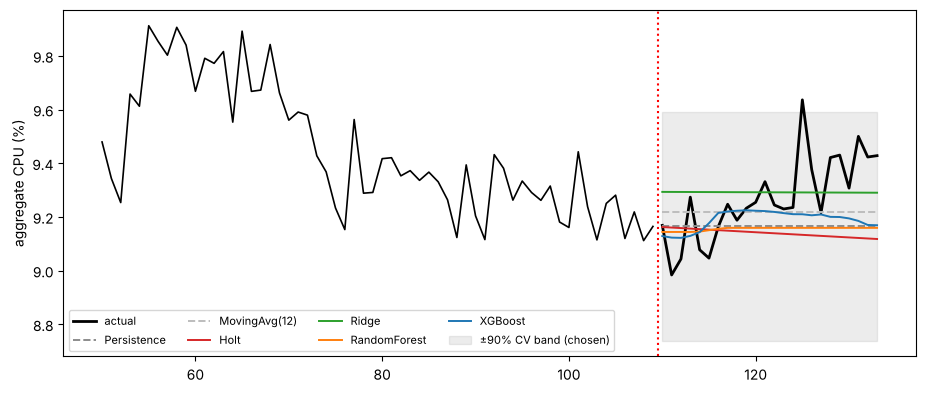

In [11]:
x_tr, x_ho = np.arange(len(train)), np.arange(len(train), len(series))
fig, ax = plt.subplots(figsize=(11,4.5))
ax.plot(x_tr[-60:], train.aggregate_cpu_utilization.to_numpy()[-60:], c="k", lw=1.2); ax.plot(x_ho, hold.aggregate_cpu_utilization, c="k", lw=2, label="actual")
for n, c in [("Persistence","#8c8c8c"),("MovingAvg(12)","#bdbdbd"),("Holt","#d62728"),("Ridge","#2ca02c"),("RandomForest","#ff7f0e"),("XGBoost","#1f77b4")]:
    ax.plot(x_ho, r.forecasts[n], c=c, lw=1.4, ls="--" if n in BASELINES else "-", label=n)
f = r.forecasts[r.chosen]; ax.fill_between(x_ho, f-r.band_q90, f+r.band_q90, color="grey", alpha=.15, label="±90% CV band (chosen)")
ax.axvline(len(train)-.5, c="r", ls=":"); ax.legend(ncol=4, fontsize=8); ax.set_ylabel("aggregate CPU (%)"); plt.show()

## 5. active_vm_count

In [12]:
rc = res["active_vm_count"]; print("chosen:", rc.chosen, "| CV MAE of every model:", rc.cv_table["MAE"].round(6).unique())
print(pd.Series(rc.forecasts[rc.chosen]).unique())

chosen: Persistence | CV MAE of every model: [0.]
[10000.]


All models tie at zero error (constant series) → tie broken toward the simplest model: forecast = last value = 10,000.

## 6. Capacity policy — margin trade-off

In [13]:
d = r.cv_preds[r.cv_preds.model == r.chosen]; margins=[0,.1,.2,.3,.4,.5,.75,1]
display(margin_tradeoff(d.y, d.pred, margins).round(3).assign(set="CV"))
display(margin_tradeoff(hold.aggregate_cpu_utilization, r.forecasts[r.chosen], margins).round(3).assign(set="holdout"))
print("90% CV error band (pp):", round(r.band_q90,3))

,margin_pp,under_rate%,mean_shortfall_pp,mean_slack_pp,set
0,0.00,32.292,0.215,0.136,CV
1,0.10,22.917,0.189,0.210,CV
2,0.20,15.625,0.157,0.291,CV
3,0.30,10.417,0.116,0.379,CV
4,0.40,6.250,0.048,0.470,CV
5,0.50,0.000,0.000,0.567,CV
6,0.75,0.000,0.000,0.817,CV
7,1.00,0.000,0.000,1.067,CV


,margin_pp,under_rate%,mean_shortfall_pp,mean_slack_pp,set
0,0.00,79.167,0.159,0.021,holdout
1,0.10,41.667,0.148,0.057,holdout
2,0.20,29.167,0.095,0.123,holdout
3,0.30,8.333,0.103,0.204,holdout
4,0.40,4.167,0.071,0.299,holdout
5,0.50,0.000,0.000,0.396,holdout
6,0.75,0.000,0.000,0.646,holdout
7,1.00,0.000,0.000,0.896,holdout


90% CV error band (pp): 0.426


## 7. Leakage checks
1. Split is done on the full series first; `run_target` receives only `series.iloc[:110]` (see `cwfc.predict`).
2. Features are built on the truncated training frame; `tests/test_features.py` proves rows ≤ t are identical with/without future rows.
3. `tests/test_pipeline.py::test_predictions_do_not_depend_on_holdout_values` rewrites the 24 holdout readings and asserts the forecasts are bit-identical.

In [14]:
import subprocess, sys
out = subprocess.run([sys.executable, "-m", "pytest", "-q", "../tests"], capture_output=True, text=True, cwd="..")
print(out.stdout[-300:])


no tests ran in 0.00s



In [15]:
import json, pathlib
pathlib.Path("../reports/results").mkdir(parents=True, exist_ok=True)
card = {t: {"chosen": x.chosen, "tuned_params": x.params, "cv_origins": x.origins, "band90_pp": x.band_q90} for t, x in res.items()}
json.dump(card, open("../reports/results/model_card.json","w"), indent=2, default=float); print(card)

{'active_vm_count': {'chosen': 'Persistence', 'tuned_params': {'Ridge': {'alpha': 0.1}, 'RandomForest': {'max_depth': 3, 'min_samples_leaf': 5}, 'XGBoost': {'max_depth': 2, 'n_estimators': 100}}, 'cv_origins': [50, 62, 74, 86], 'band90_pp': 0.0}, 'aggregate_cpu_utilization': {'chosen': 'Persistence', 'tuned_params': {'Ridge': {'alpha': 1000.0}, 'RandomForest': {'max_depth': 3, 'min_samples_leaf': 5}, 'XGBoost': {'max_depth': 3, 'n_estimators': 300}}, 'cv_origins': [50, 62, 74, 86], 'band90_pp': 0.42587910876081203}}
